# [Project title]

**Team members:** [Names]  
**Repository:** [URL of your team's fork]

## Setup

Use relative paths and keep the notebook runnable from beginning to end.

In [2]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)


In [3]:


adeline_url = "https://raw.githubusercontent.com/AdelineKwakye/project_template/adeline-data-cleaning/data/"

andrew_url = "https://raw.githubusercontent.com/AdelineKwakye/project_template/andrew-linear-regression/data/"

flu_df = pd.read_csv(adeline_url + "target-hospital-admissions.csv")
cleaned_df = pd.read_csv(adeline_url + "flu_cleaned.csv")
predictions = pd.read_csv(andrew_url + "predictions.csv")

print("Original dataset:", flu_df.shape)
print("Cleaned dataset:", cleaned_df.shape)
print("Predictions dataset:", predictions.shape)

display(cleaned_df.head())


Original dataset: (13144, 5)
Cleaned dataset: (12400, 5)
Predictions dataset: (11891, 6)


,date,location,location_name,value,weekly_rate
0,2026-10-31,37,North Carolina,202.0,1.828712
1,2026-10-31,42,Pennsylvania,557.0,4.258816
2,2026-10-31,4,Arizona,138.0,1.820008
3,2026-10-31,54,West Virginia,23.0,1.299450
4,2026-10-31,33,New Hampshire,27.0,1.916209


## Load data

## Prepare data

In [4]:
# Clean data and create features.

# cleaning data
    # steps to do:
    # convert to date time
    # check if weekly date interval
    # handle missing values
    # filter out non-U.S states

# convert date to date time
flu_df["date"] = pd.to_datetime(flu_df["date"])

date_gaps = (
    flu_df.sort_values(["location", "date"])
    .groupby("location")["date"]
    .diff()
    .dt.days
)

print(date_gaps.value_counts().sort_index())
    # note: all 13,091 date intervals are 7 days apart

print("zero hospitilization count: ", (flu_df["value"] == 0).sum())
    # note: 1054
# check if any negative hospitilizations
print("negative hospitilization counts: ", (flu_df["value"]< 0).sum())
    # note: 0
display(flu_df["value"].describe())
    #13,108 non missing hospitilization values
    # mean = 224.60 average weekly count across locations
    # median = 20
        # could be right-skewed
    # max = largest weekly count

# clean the data
flu_clean = flu_df.copy()
print(flu_clean.isna().sum())

    # leave missing rows since imputing missing to be unknown would
    # change the entire value and weekly_rate column to be a str rather than a numeric value

# convert to datetime
flu_clean["date"] = pd.to_datetime(flu_clean["date"])
print(flu_clean["date"].dtype)
print(flu_clean.dtypes)

# strip any white spaces
flu_clean["location_name"] = flu_clean["location_name"].str.strip()
flu_clean["location"] = flu_clean["location"].str.strip()

# only keep the 50 States in the US
sorted(flu_clean["location_name"].unique())

exclude_locations = ["District of Columbia", "Puerto Rico", "US"]
flu_clean = flu_clean.drop(
    flu_clean[flu_clean["location_name"].isin(exclude_locations)].index
)
# check
print("Rows:", len(flu_clean))
print("Location:", flu_clean["location_name"].nunique())

# save cleaned csv
flu_clean.to_csv(DATA_DIR / "flu_cleaned.csv", index=False)

date
7.0    13091
Name: count, dtype: int64
zero hospitilization count:  1054
negative hospitilization counts:  0


,value
count,13108.000000
mean,224.596277
std,1585.864307
min,0.000000
25%,5.000000
50%,20.000000
75%,88.000000
max,55544.000000


date              0
location          0
location_name     0
value            36
weekly_rate      36
dtype: int64
datetime64[ns]
date             datetime64[ns]
location                 object
location_name            object
value                   float64
weekly_rate             float64
dtype: object
Rows: 12400
Location: 50


### Feature engineering and chronological splitting

The prediction target is the number of influenza hospital admissions
in a state during the target week. Predictors are constructed using
hospitalization observations from preceding weeks, seasonal information,
and state identity.

Missing observations are not treated as zero. Rows without sufficient
historical observations are excluded from modeling.

Training, validation, and test sets are separated chronologically
to prevent future observations from entering model training.


In [5]:
import pandas as pd
import numpy as np

# Load the cleaned state-level dataset
panel = pd.read_csv(
    DATA_DIR / "flu_cleaned.csv",
    dtype={"location": "string"},
    parse_dates=["date"]
)

panel = panel.rename(columns={
    "location": "state",
    "location_name": "state_name",
    "date": "week",
    "value": "hospitalizations"
})

panel = panel.sort_values(
    ["state", "week"]
).reset_index(drop=True)

# Validate geographic identifiers and weekly observations
assert panel["state"].str.fullmatch(r"[0-9]{2}").all()
assert not panel.duplicated(["state", "week"]).any()
assert panel["state"].nunique() == 50

gaps = panel.groupby("state")["week"].diff().dropna()
assert gaps.eq(pd.Timedelta(days=7)).all()

# Construct lag features separately for each state
grouped = panel.groupby("state")["hospitalizations"]

for lag in range(1, 5):
    panel[f"lag_{lag}"] = grouped.shift(lag)

lag_columns = [f"lag_{i}" for i in range(1, 5)]

# Historical averages and changes
panel["rolling_mean_4"] = panel[lag_columns].mean(
    axis=1, skipna=False
)

panel["weekly_change"] = panel["lag_1"] - panel["lag_2"]

# Cyclical seasonal features
day = panel["week"].dt.dayofyear - 1
panel["season_sin"] = np.sin(2 * np.pi * day / 365.25)
panel["season_cos"] = np.cos(2 * np.pi * day / 365.25)

# Exclude incomplete historical windows and missing targets
required = lag_columns + ["hospitalizations"]
model_df = panel.dropna(subset=required).copy()

# Exclude the incomplete 2026-27 season
model_df = model_df[
    model_df["week"] < pd.Timestamp("2026-10-01")
].copy()

# Chronological splits based on the target week
model_df["split"] = np.select(
    [
        model_df["week"] < pd.Timestamp("2024-10-01"),
        model_df["week"] < pd.Timestamp("2025-10-01")
    ],
    ["train", "validation"],
    default="test"
)

train_df = model_df[model_df["split"] == "train"].copy()
validation_df = model_df[
    model_df["split"] == "validation"
].copy()
test_df = model_df[model_df["split"] == "test"].copy()

# Confirm chronological separation
assert train_df["week"].max() < validation_df["week"].min()
assert validation_df["week"].max() < test_df["week"].min()
assert not model_df[required].isna().any().any()

print("Original cleaned observations:", len(panel))
print("Modeling observations:", len(model_df))
print("Number of states:", model_df["state"].nunique())

print("\nSplit summary:")
print(model_df.groupby("split").agg(
    observations=("week", "size"),
    start_date=("week", "min"),
    end_date=("week", "max"),
    states=("state", "nunique")
).to_string())

print("\nExample feature rows:")
print(model_df[[
    "state", "week", "hospitalizations",
    "lag_1", "lag_2", "lag_3", "lag_4",
    "rolling_mean_4", "weekly_change"
]].head(10).to_string(index=False))

print("\nFeature engineering checks passed.")

Original cleaned observations: 12400
Modeling observations: 11891
Number of states: 50

Split summary:
            observations start_date   end_date  states
split                                                 
test                2600 2025-10-04 2026-09-26      50
train               6706 2022-03-05 2024-09-28      50
validation          2585 2024-10-05 2025-09-27      50

Example feature rows:
state       week  hospitalizations  lag_1  lag_2  lag_3  lag_4  rolling_mean_4  weekly_change
   01 2022-03-05              20.0   10.0   21.0    8.0    5.0           11.00          -11.0
   01 2022-03-12              35.0   20.0   10.0   21.0    8.0           14.75           10.0
   01 2022-03-19              23.0   35.0   20.0   10.0   21.0           21.50           15.0
   01 2022-03-26              17.0   23.0   35.0   20.0   10.0           22.00          -12.0
   01 2022-04-02              25.0   17.0   23.0   35.0   20.0           23.75           -6.0
   01 2022-04-09              21.0 

## Explore data

In [6]:
# Summarize and visualize the prepared data.

This section examines the cleaned influenza hospitalization dataset to understand its structure, distribution, and trends over time and across states. Descriptive statistics and visualizations are used to identify patterns, variability, and potential anomalies before evaluating the forecasting models.

In [7]:

eda = panel[["state", "state_name", "week", "hospitalizations", "weekly_rate"]].copy()

print("Dataset dimensions:", eda.shape)
print("\nColumn names:", eda.columns.tolist())

print("\nData types:")
print(eda.dtypes)

print("\nDescriptive statistics:")
display(eda[["hospitalizations", "weekly_rate"]].describe())

print("\nDate range:", eda["week"].min().date(), "to", eda["week"].max().date())
print("Number of states:", eda["state"].nunique())
print("Weeks per state:", eda.groupby("state")["week"].nunique().unique())

print("\nMissing values:")
print(eda.isnull().sum())
print("\nDuplicate state-week rows:", eda.duplicated(["state", "week"]).sum())
print("Zero-hospitalization rows:", (eda["hospitalizations"] == 0).sum())

print("\nMean:", round(eda["hospitalizations"].mean(), 1))
print("Median:", eda["hospitalizations"].median())

Dataset dimensions: (12400, 5)

Column names: ['state', 'state_name', 'week', 'hospitalizations', 'weekly_rate']

Data types:
state               string[python]
state_name                  object
week                datetime64[ns]
hospitalizations           float64
weekly_rate                float64
dtype: object

Descriptive statistics:


,hospitalizations,weekly_rate
count,12364.000000,12364.000000
mean,116.681333,1.736727
std,317.600372,3.319666
min,0.000000,0.000000
25%,5.000000,0.134643
50%,19.000000,0.408707
75%,82.000000,1.616447
max,4729.000000,37.534369



Date range: 2022-02-05 to 2026-10-31
Number of states: 50
Weeks per state: [248]

Missing values:
state                0
state_name           0
week                 0
hospitalizations    36
weekly_rate         36
dtype: int64

Duplicate state-week rows: 0
Zero-hospitalization rows: 1005

Mean: 116.7
Median: 19.0


Weeks with at least one missing state: 17


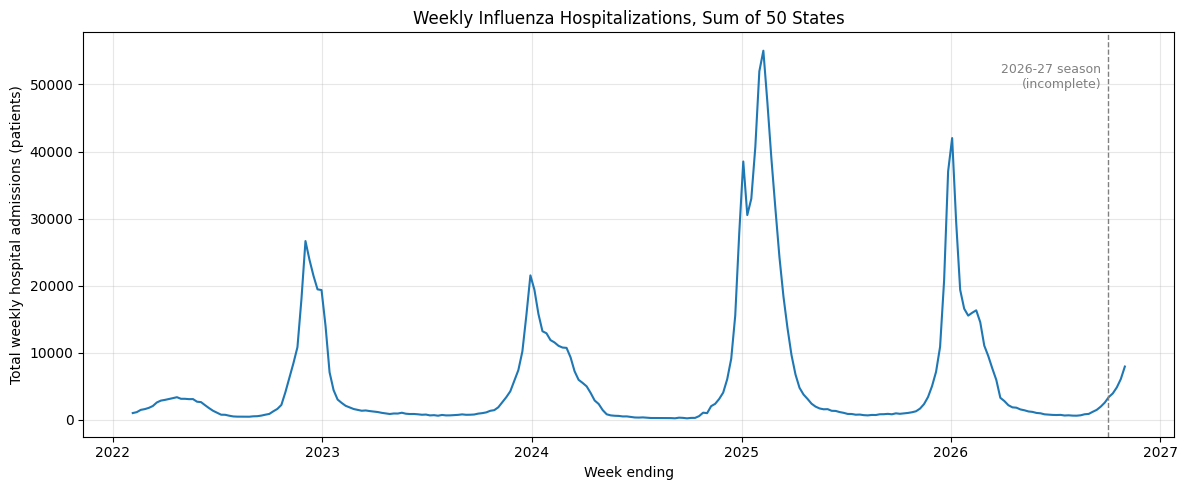


Peak week in each season:
      week  hospitalizations  season_start_year
2022-04-23            3371.0               2021
2022-12-03           26652.0               2022
2023-12-30           21537.0               2023
2025-02-08           55034.0               2024
2026-01-03           42008.0               2025
2026-10-31            7940.0               2026


In [8]:
# Graph 1: Total weekly influenza hospitalizations across the 50 states

weekly_totals = eda.groupby("week")["hospitalizations"].sum()

# Sums skip missing values, so check how many weeks are affected
missing_per_week = eda.groupby("week")["hospitalizations"].apply(lambda s: s.isna().sum())
print("Weeks with at least one missing state:", (missing_per_week > 0).sum())

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(weekly_totals.index, weekly_totals.values, linewidth=1.5)

# Mark where the incomplete 2026-27 season begins
ax.axvline(pd.Timestamp("2026-10-01"), color="gray", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2026-09-20"), weekly_totals.max() * 0.9,
        "2026-27 season\n(incomplete)", ha="right", fontsize=9, color="gray")

ax.set_title("Weekly Influenza Hospitalizations, Sum of 50 States")
ax.set_xlabel("Week ending")
ax.set_ylabel("Total weekly hospital admissions (patients)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Peak week for each flu season (seasons run July to June)
tot = weekly_totals.reset_index()
tot["season_start_year"] = np.where(tot["week"].dt.month >= 7,
                                    tot["week"].dt.year,
                                    tot["week"].dt.year - 1)
peaks = tot.loc[tot.groupby("season_start_year")["hospitalizations"].idxmax()]
print("\nPeak week in each season:")
print(peaks.to_string(index=False))

Figure 1 shows total weekly influenza hospital admissions summed across the 50 states from February 2022 to October 2026. Activity follows a repeated winter pattern, with a peak each season between early December and early February and low counts through summer. Peak size varies a lot: the 2024-25 season peaked near 55,000 admissions, about 2.5 times the 2023-24 peak of roughly 21,500. This matters for forecasting because both timing and magnitude shift from year to year, so a model trained on past seasons may not anticipate a larger surge. The most recent season is incomplete, and 17 weeks have at least one state missing, so totals in those weeks are slightly understated.

Highest 3 by total: ['Texas', 'Florida', 'California']
Lowest 3 by total: ['Wyoming', 'Alaska', 'Vermont']


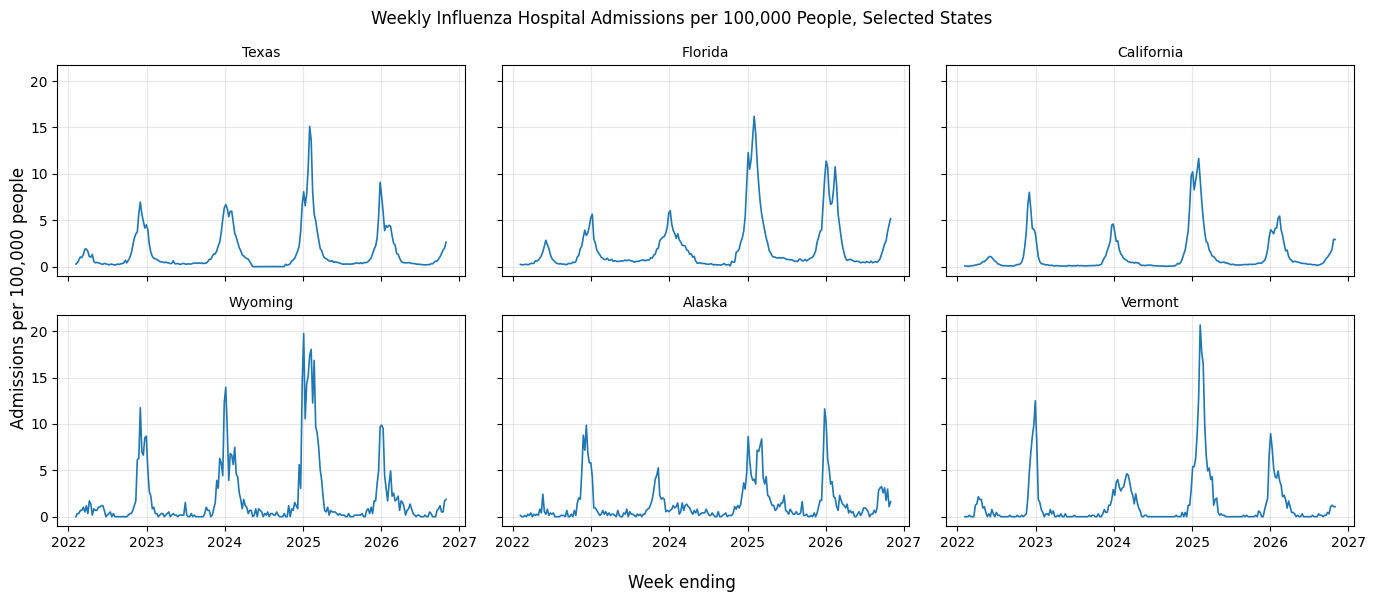


Peak weekly rate per 100k, by state:
state_name
Vermont       20.7
Wyoming       19.7
Florida       16.2
Texas         15.1
California    11.7
Alaska        11.6
Name: weekly_rate, dtype: float64


In [9]:
# Graph 2: State-level trends using weekly_rate (admissions per 100,000 people)
# We use the rate, not raw counts, so big and small states are comparable.

# Pick 6 states by TOTAL hospitalizations (largest 3) and smallest-population-like
# (lowest 3 totals), using the whole dataset. This is a descriptive choice, not a model choice.
state_totals = eda.groupby("state_name")["hospitalizations"].sum().sort_values(ascending=False)
print("Highest 3 by total:", state_totals.head(3).index.tolist())
print("Lowest 3 by total:", state_totals.tail(3).index.tolist())

selected = state_totals.head(3).index.tolist() + state_totals.tail(3).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True, sharey=True)
for ax, name in zip(axes.flat, selected):
    sub = eda[eda["state_name"] == name].sort_values("week")
    ax.plot(sub["week"], sub["weekly_rate"], linewidth=1.2)
    ax.set_title(name, fontsize=10)
    ax.grid(alpha=0.3)

fig.suptitle("Weekly Influenza Hospital Admissions per 100,000 People, Selected States")
fig.supxlabel("Week ending")
fig.supylabel("Admissions per 100,000 people")
plt.tight_layout()
plt.show()

# Peak rate in each selected state, to quantify differences
print("\nPeak weekly rate per 100k, by state:")
print(eda[eda["state_name"].isin(selected)]
      .groupby("state_name")["weekly_rate"].max().round(1).sort_values(ascending=False))

Figure 2 compares weekly influenza admissions per 100,000 residents in the three states with the highest and the three with the lowest total admissions. All six states show winter peaks in the same seasons, suggesting a shared national seasonal pattern. Peak rates still differ across states, from 11.6 per 100,000 in Alaska to 20.7 in Vermont, and the low-volume states show more week-to-week jaggedness. This suggests that state identity and small-count noise may matter for forecasting. Only six states are shown, chosen by total count, so this does not describe all 50 states.

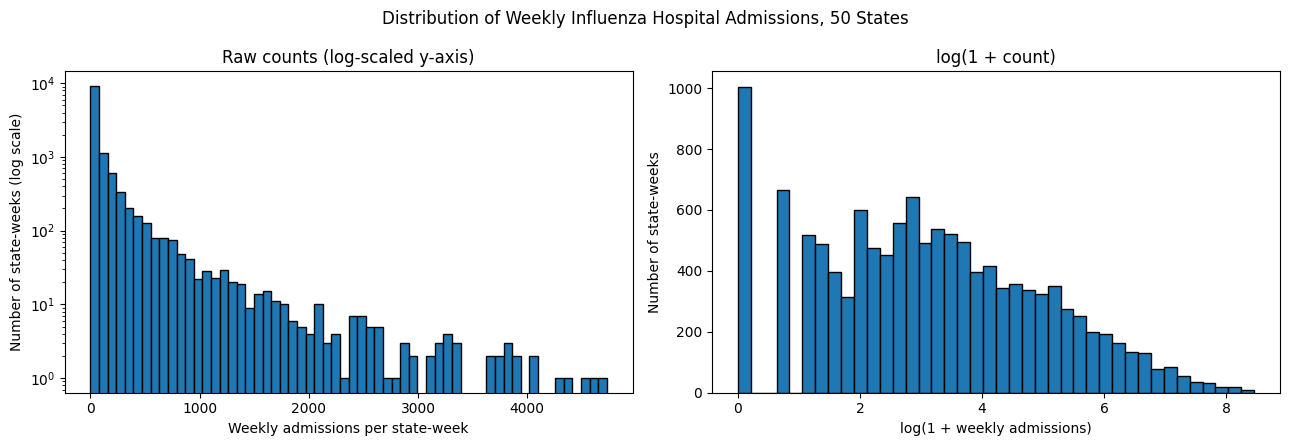

Observations: 12364
Mean: 116.7 | Median: 19.0
90th percentile: 276.0 | 99th percentile: 1596.369999999999
Max: 4729.0
Share of weeks with 0 admissions: 8.1 %
Share of weeks under 50 admissions: 67.7 %
Skewness: 6.37


In [10]:
# Graph 3: Distribution of weekly hospitalization counts (50 states)
vals = eda["hospitalizations"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: raw counts, log-scaled y-axis so the tail is visible
axes[0].hist(vals, bins=60, edgecolor="black")
axes[0].set_yscale("log")
axes[0].set_title("Raw counts (log-scaled y-axis)")
axes[0].set_xlabel("Weekly admissions per state-week")
axes[0].set_ylabel("Number of state-weeks (log scale)")

# Right: log of (count + 1), which handles the zeros
axes[1].hist(np.log1p(vals), bins=40, edgecolor="black")
axes[1].set_title("log(1 + count)")
axes[1].set_xlabel("log(1 + weekly admissions)")
axes[1].set_ylabel("Number of state-weeks")

fig.suptitle("Distribution of Weekly Influenza Hospital Admissions, 50 States")
plt.tight_layout()
plt.show()

# Numbers for the write-up
print("Observations:", len(vals))
print("Mean:", round(vals.mean(), 1), "| Median:", vals.median())
print("90th percentile:", vals.quantile(0.90), "| 99th percentile:", vals.quantile(0.99))
print("Max:", vals.max())
print("Share of weeks with 0 admissions:", round((vals == 0).mean() * 100, 1), "%")
print("Share of weeks under 50 admissions:", round((vals < 50).mean() * 100, 1), "%")
print("Skewness:", round(vals.skew(), 2))

Figure 3 shows the distribution of weekly admissions across all state-weeks, on a log-scaled axis (left) and as log(1 + count) (right). The distribution is strongly right-skewed (skewness 6.37): the median is 19 admissions but the mean is 116.7, and 67.7% of state-weeks have fewer than 50 admissions. A small number of state-weeks reach into the thousands, with a maximum of 4,729. This matters for evaluation because large-state surge weeks are rare but dominate squared-error metrics like RMSE, so RMSE and MAE can tell different stories. Because the counts depend on state population, this pooled distribution mixes states of very different sizes.

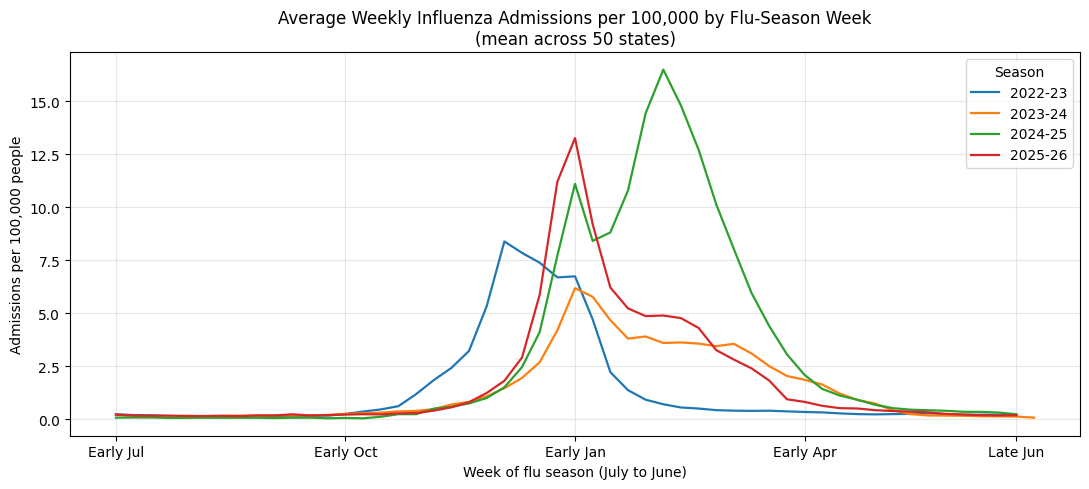

Peak of the 50-state average rate, by season:
  2022-23: season week 23, rate 8.39 per 100k
  2023-24: season week 27, rate 6.19 per 100k
  2024-25: season week 32, rate 16.50 per 100k
  2025-26: season week 27, rate 13.27 per 100k

Share of total weekly rate falling in Dec-Feb: 71.6%


In [11]:
# Graph 4: Seasonal pattern by flu-season week (July to June)
# Uses the weekly rate (per 100k) so big and small states count equally.

s = eda.dropna(subset=["weekly_rate"]).copy()

# Flu season starts in July: Jul-Dec belongs to that year's season, Jan-Jun to the previous year's
s["season"] = np.where(s["week"].dt.month >= 7, s["week"].dt.year, s["week"].dt.year - 1)

# Only complete seasons: 2022-23, 2023-24, 2024-25, 2025-26
complete = s[s["season"].between(2022, 2025)].copy()

# Week number within the season (1 = first week on or after July 1)
season_start = pd.to_datetime(complete["season"].astype(str) + "-07-01")
complete["season_week"] = ((complete["week"] - season_start).dt.days // 7) + 1

# Average across states for each season and season-week
avg = (complete.groupby(["season", "season_week"])["weekly_rate"]
       .mean().reset_index())

fig, ax = plt.subplots(figsize=(11, 5))
for season, grp in avg.groupby("season"):
    ax.plot(grp["season_week"], grp["weekly_rate"],
            label=f"{season}-{str(season + 1)[-2:]}", linewidth=1.6)

# Label x-axis with approximate months (season week 1 is early July)
ticks = [1, 14, 27, 40, 52]
ax.set_xticks(ticks)
ax.set_xticklabels(["Early Jul", "Early Oct", "Early Jan", "Early Apr", "Late Jun"])
ax.set_title("Average Weekly Influenza Admissions per 100,000 by Flu-Season Week\n(mean across 50 states)")
ax.set_xlabel("Week of flu season (July to June)")
ax.set_ylabel("Admissions per 100,000 people")
ax.legend(title="Season")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Numbers for the write-up: peak week and size for each season
print("Peak of the 50-state average rate, by season:")
for season, grp in avg.groupby("season"):
    top = grp.loc[grp["weekly_rate"].idxmax()]
    print(f"  {season}-{str(season + 1)[-2:]}: season week {int(top['season_week'])}, "
          f"rate {top['weekly_rate']:.2f} per 100k")

# Share of admissions falling in Dec-Feb
winter = complete["week"].dt.month.isin([12, 1, 2])
share = complete.loc[winter, "weekly_rate"].sum() / complete["weekly_rate"].sum()
print(f"\nShare of total weekly rate falling in Dec-Feb: {share * 100:.1f}%")

Figure 4 overlays the 50-state average weekly admission rate by week of the flu season (July to June) for the four complete seasons. Every season rises in winter and declines by spring, and 71.6% of the summed weekly rate falls in December to February, so time of year carries information about activity. However, the peak ranged from season week 23 (early December, 2022-23) to week 32 (early February, 2024-25), and peak size ranged from 6.19 to 16.50 per 100,000. A fixed seasonal curve will therefore not line up with each year's peak. With only four complete seasons, this is limited evidence about how stable seasonality is.

### Exploratory Data Analysis Findings

The cleaned dataset has 12,400 state-week observations covering 50 states, with 248 weekly observations per state from 2022-02-05 to 2026-10-31. 36 observations are missing (not imputed) and 1,005 are true zeros. The 2026-27 season is incomplete, covering only about one month.

**1. Weekly trends (Figure 1).** Total weekly admissions across the 50 states show a winter peak every season and low counts through summer. Peak size varies widely: about 55,000 in 2024-25 versus about 21,500 in 2023-24. Timing and magnitude both change year to year, which makes forecasting harder. 17 weeks have at least one state missing, so totals in those weeks are slightly understated.

**2. State-level differences (Figure 2).** Using admissions per 100,000 people, the three highest-volume and three lowest-volume states peak in the same seasons, suggesting a shared national pattern. Peak rates still range from 11.6 (Alaska) to 20.7 (Vermont) per 100,000, and low-volume states look noisier. Only six states are shown, selected by total count.

**3. Distribution (Figure 3).** Weekly counts are strongly right-skewed (skewness 6.37). The median is 19 but the mean is 116.7, and 67.7% of state-weeks have fewer than 50 admissions. Rare large-state surge weeks (maximum 4,729) will dominate squared-error metrics such as RMSE.

**4. Seasonality (Figure 4).** 71.6% of the summed weekly rate falls in December to February, so time of year is informative. But the peak week ranged from season week 23 to 32 and peak size from 6.19 to 16.50 per 100,000 across the four complete seasons, so seasonal timing is not fixed. Four seasons is limited evidence.

**Summary.** The data are seasonal, skewed, and heterogeneous across states and years. These are descriptive patterns only and do not show that any variable causes or predicts hospitalizations. They motivate evaluating with both MAE and RMSE on a chronological split.


## Build models

### Persistence baseline and linear regression

The persistence baseline predicts that hospitalizations in the target
week will equal hospitalizations in the preceding week.

Four linear regression feature configurations are compared using
validation MAE. The configuration with the lowest validation MAE
is selected before examining test performance.

After selection, the final model is refitted using training and
validation data, then applied to the held-out test period.

Negative hospitalization predictions are clipped to zero because
hospitalization counts cannot be negative.

Training and validation predictions come from the selected model
fitted on training data only. Test predictions come from the
refitted model.

The evaluation uses finalized historical CDC records rather than
real-time reporting snapshots, which may introduce revision-related
limitations.


In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

target = "hospitalizations"

# Candidate feature configurations
feature_sets = {
    "Lag 1": ["lag_1"],
    "Lags 1-4": lag_columns,
    "Lags + seasonality": lag_columns + [
        "season_sin", "season_cos"
    ],
    "Lags + seasonality + state": lag_columns + [
        "season_sin", "season_cos", "state"
    ]
}

def build_regression(features):
    numeric = [f for f in features if f != "state"]

    transformers = [
        ("numeric", "passthrough", numeric)
    ]

    if "state" in features:
        transformers.append((
            "state",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            ["state"]
        ))

    return Pipeline([
        ("preprocessing", ColumnTransformer(transformers)),
        ("regression", LinearRegression())
    ])

def predict_counts(model, frame, features):
    return np.maximum(
        model.predict(frame[features]), 0
    )

def calculate_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    }

# Persistence baseline on validation data
baseline_metrics = calculate_metrics(
    validation_df[target],
    validation_df["lag_1"]
)

validation_results = []
candidate_models = {}

# Fit candidates using training data only
for name, features in feature_sets.items():
    model = build_regression(features)

    model.fit(
        train_df[features],
        train_df[target]
    )

    val_pred = predict_counts(
        model, validation_df, features
    )

    metrics = calculate_metrics(
        validation_df[target], val_pred
    )

    validation_results.append({
        "configuration": name,
        **metrics
    })

    candidate_models[name] = model

validation_results = pd.DataFrame(
    validation_results
).sort_values("MAE", kind="stable")

# Select configuration without using test outcomes
best_name = validation_results.iloc[0]["configuration"]
best_features = feature_sets[best_name]
selected_model = candidate_models[best_name]

print("VALIDATION RESULTS")
print(
    validation_results.round(3).to_string(index=False)
)

print("\nPersistence validation metrics:")
print({
    k: round(v, 3)
    for k, v in baseline_metrics.items()
})

print("\nSelected configuration:", best_name)
print("Selected features:", best_features)

# Refit the selected configuration on all pre-test data
development_df = pd.concat(
    [train_df, validation_df],
    ignore_index=True
)

assert development_df["week"].max() < test_df["week"].min()

final_model = build_regression(best_features)

final_model.fit(
    development_df[best_features],
    development_df[target]
)

# Generate the prediction handoff
prediction_frames = []

for split_name, frame in [
    ("train", train_df),
    ("validation", validation_df),
    ("test", test_df)
]:
    model = (
        final_model if split_name == "test"
        else selected_model
    )

    result = frame[[
        "state", "week", target
    ]].copy()

    result = result.rename(
        columns={target: "actual"}
    )

    result["predicted_linear_regression"] = (
        predict_counts(model, frame, best_features)
    )

    result["predicted_baseline"] = (
        frame["lag_1"].to_numpy()
    )

    result["split"] = split_name

    prediction_frames.append(result)

predictions = pd.concat(
    prediction_frames, ignore_index=True
).sort_values(["week", "state"]).reset_index(drop=True)

# Validate prediction integrity
assert len(predictions) == len(model_df)
assert not predictions.duplicated(
    ["state", "week"]
).any()

prediction_columns = [
    "actual",
    "predicted_linear_regression",
    "predicted_baseline"
]

assert np.isfinite(
    predictions[prediction_columns].to_numpy()
).all()

assert predictions[prediction_columns].ge(0).all().all()

# Independently verify persistence against previous week
history = panel[[
    "state", "week", "hospitalizations"
]].copy()

history["week"] += pd.Timedelta(days=7)

history = history.rename(
    columns={"hospitalizations": "previous_actual"}
)

audit = predictions.merge(
    history,
    on=["state", "week"],
    validate="one_to_one"
)

assert len(audit) == len(predictions)
assert np.allclose(
    audit["predicted_baseline"],
    audit["previous_actual"]
)

# Save predictions for the evaluation section
predictions.to_csv(
    DATA_DIR / "predictions.csv",
    index=False
)

print("\nPrediction counts:")
print(predictions["split"].value_counts())

print("\nSample test predictions:")
print(
    predictions[predictions["split"] == "test"]
    .head(10).round(3).to_string(index=False)
)

print("\nAll prediction integrity checks passed.")
print("Saved data/predictions.csv")

VALIDATION RESULTS
             configuration    MAE    RMSE
                  Lags 1-4 44.006 115.776
        Lags + seasonality 44.106 115.396
Lags + seasonality + state 44.193 116.017
                     Lag 1 54.573 141.949

Persistence validation metrics:
{'MAE': 55.426, 'RMSE': np.float64(143.13)}

Selected configuration: Lags 1-4
Selected features: ['lag_1', 'lag_2', 'lag_3', 'lag_4']

Prediction counts:
split
train         6706
test          2600
validation    2585
Name: count, dtype: int64

Sample test predictions:
state       week  actual  predicted_linear_regression  predicted_baseline split
   01 2025-10-04    21.0                       29.598                18.0  test
   02 2025-10-04     2.0                       10.858                 1.0  test
   04 2025-10-04    19.0                       17.077                13.0  test
   05 2025-10-04     4.0                       18.533                 9.0  test
   06 2025-10-04    92.0                      120.746               1

## Evaluate models

In [13]:

# Compare models using MAE and RMSE

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Evaluate only the held-out test data
test_data = predictions[predictions["split"] == "test"].copy()

actual = test_data["actual"]
linear_predictions = test_data["predicted_linear_regression"]
baseline_predictions = test_data["predicted_baseline"]

# Calculate evaluation metrics
results = pd.DataFrame({
    "Model": ["Persistence Baseline", "Linear Regression"],
    "MAE": [
        mean_absolute_error(actual, baseline_predictions),
        mean_absolute_error(actual, linear_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual, baseline_predictions)),
        np.sqrt(mean_squared_error(actual, linear_predictions))
    ]
})

print("Model Performance on Test Data")
display(results.round(3))

# Calculate residuals for further analysis
test_data["linear_residual"] = actual - linear_predictions
test_data["baseline_residual"] = actual - baseline_predictions

print("\nLinear Regression Residual Summary")
display(test_data["linear_residual"].describe().round(3))


Model Performance on Test Data


,Model,MAE,RMSE
0,Persistence Baseline,39.507,118.412
1,Linear Regression,34.517,95.096



Linear Regression Residual Summary


,linear_residual
count,2600.000
mean,0.958
std,95.110
min,-1323.459
25%,-11.004
50%,-5.101
75%,4.386
max,927.106


## Final results

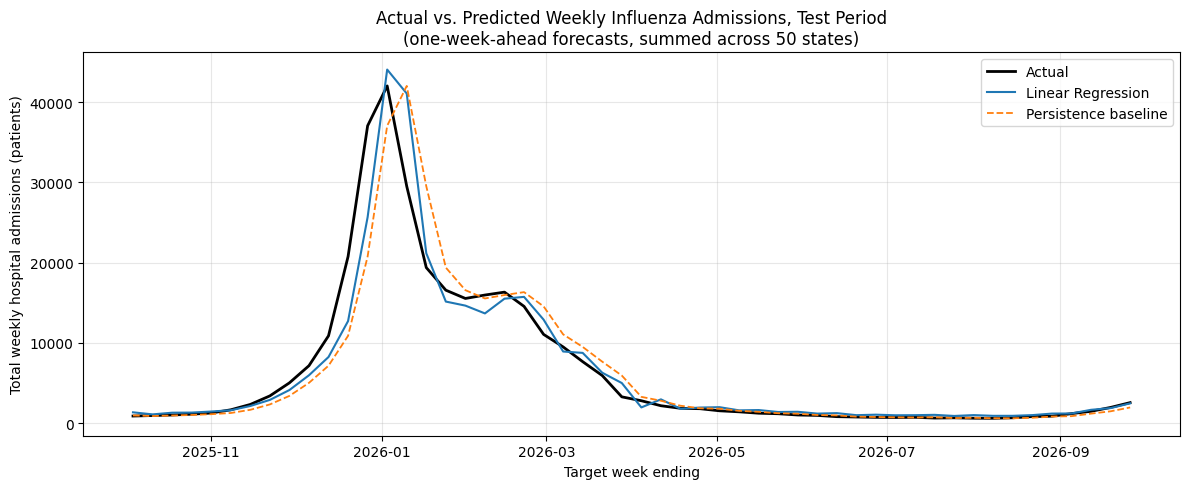

Test weeks: 52 | states per week: [50]
Date range: 2025-10-04 to 2026-09-26

Actual peak week: 2026-01-03
  Actual total:              42008
  Linear Regression predicted: 44045
  Baseline predicted:          37044


In [14]:
# Graph 5: Actual vs. predicted weekly admissions over the test period
# One-week-ahead forecasts, summed across the 50 states for readability.
test = predictions[predictions["split"] == "test"]

weekly = test.groupby("week")[["actual", "predicted_linear_regression", "predicted_baseline"]].sum()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(weekly.index, weekly["actual"], color="black", linewidth=2, label="Actual")
ax.plot(weekly.index, weekly["predicted_linear_regression"], color="tab:blue", linewidth=1.5, label="Linear Regression")
ax.plot(weekly.index, weekly["predicted_baseline"], color="tab:orange", linewidth=1.3, linestyle="--", label="Persistence baseline")
ax.set_title("Actual vs. Predicted Weekly Influenza Admissions, Test Period\n(one-week-ahead forecasts, summed across 50 states)")
ax.set_xlabel("Target week ending")
ax.set_ylabel("Total weekly hospital admissions (patients)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Numbers for the write-up
peak_week = weekly["actual"].idxmax()
print("Test weeks:", len(weekly), "| states per week:", test.groupby("week")["state"].nunique().unique())
print("Date range:", weekly.index.min().date(), "to", weekly.index.max().date())
print("\nActual peak week:", peak_week.date())
print("  Actual total:             ", round(weekly.loc[peak_week, "actual"]))
print("  Linear Regression predicted:", round(weekly.loc[peak_week, "predicted_linear_regression"]))
print("  Baseline predicted:         ", round(weekly.loc[peak_week, "predicted_baseline"]))

Figure 5 compares actual weekly admissions with one-week-ahead forecasts from Linear Regression and the persistence baseline over the test season (October 2025 to September 2026), summed across the 50 states. Both methods track the seasonal rise and fall, but the baseline trails the actual curve by about one week by construction. Linear Regression follows the rise more closely and reaches a peak near the actual one (about 44,000 predicted versus 42,008 actual in the week ending 2026-01-03). However, the model stays high in the weeks right after the peak, when actual admissions drop faster. The figure sums over states for readability, while the reported MAE and RMSE are computed per state-week, and the test set covers only one flu season.

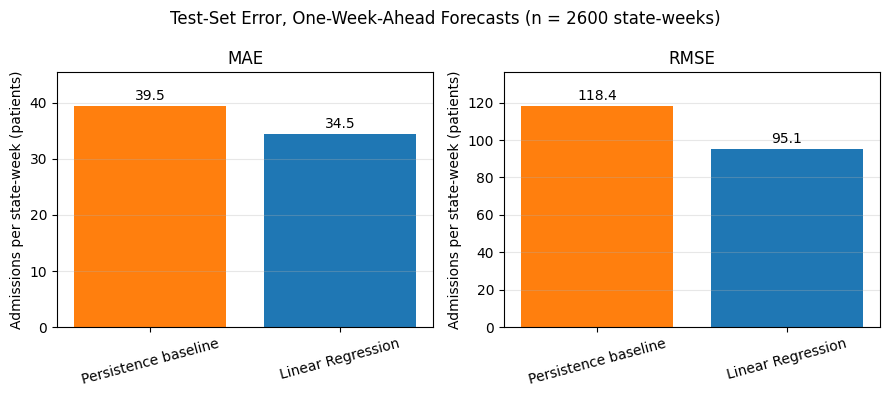

MAE:  baseline 39.507 | LR 34.517 | improvement 12.6%
RMSE: baseline 118.412 | LR 95.096 | improvement 19.7%


In [15]:
# Graph 6: MAE and RMSE on the held-out test set, per state-week
from sklearn.metrics import mean_absolute_error, mean_squared_error

t = predictions[predictions["split"] == "test"]
models = {
    "Persistence baseline": t["predicted_baseline"],
    "Linear Regression": t["predicted_linear_regression"],
}

mae = [mean_absolute_error(t["actual"], p) for p in models.values()]
rmse = [np.sqrt(mean_squared_error(t["actual"], p)) for p in models.values()]

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, vals, name in zip(axes, [mae, rmse], ["MAE", "RMSE"]):
    bars = ax.bar(list(models.keys()), vals, color=["tab:orange", "tab:blue"])
    ax.bar_label(bars, fmt="%.1f", padding=2)
    ax.set_title(name)
    ax.set_ylabel("Admissions per state-week (patients)")
    ax.set_ylim(0, max(vals) * 1.15)
    ax.tick_params(axis="x", labelrotation=15)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(f"Test-Set Error, One-Week-Ahead Forecasts (n = {len(t)} state-weeks)")
plt.tight_layout()
plt.show()

print(f"MAE:  baseline {mae[0]:.3f} | LR {mae[1]:.3f} | improvement {100*(mae[0]-mae[1])/mae[0]:.1f}%")
print(f"RMSE: baseline {rmse[0]:.3f} | LR {rmse[1]:.3f} | improvement {100*(rmse[0]-rmse[1])/rmse[0]:.1f}%")

Figure 6 compares test-set error for the two methods on the same 2,600 state-week observations. Linear Regression has a lower MAE (34.5 vs. 39.5 admissions per state-week, about 12.6% lower) and a lower RMSE (95.1 vs. 118.4, about 19.7% lower). The larger improvement in RMSE suggests the model's gain comes partly from reducing large errors, though both metrics are pooled across states, so large states influence them most. These results cover a single test season and do not show how the model would perform in other years.

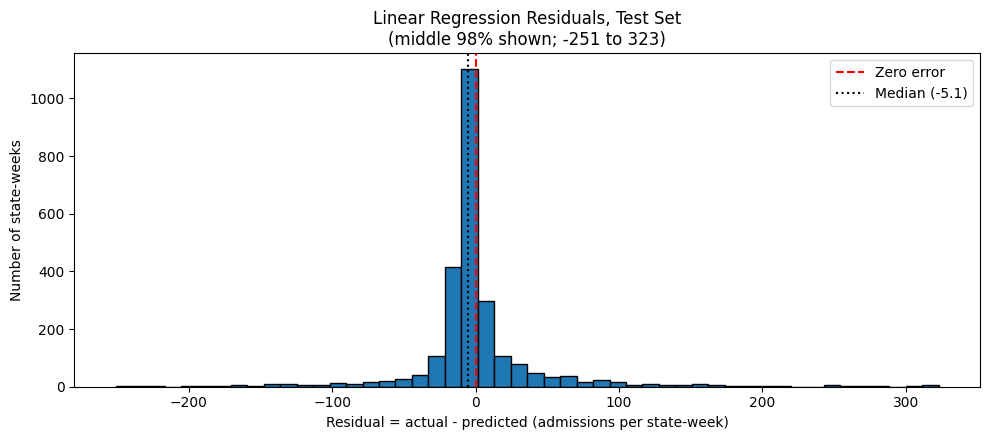

Mean residual: 0.96 | Median: -5.1
Share overpredicted (resid < 0): 67.3 %
Share underpredicted (resid > 0): 32.7 %
Share within +/- 10 admissions: 52.3 %

Five largest overpredictions:
state       week  actual  predicted_linear_regression   resid
   42 2026-01-10  2248.0                       3571.5 -1323.5
   36 2026-01-10  2387.0                       3552.2 -1165.2
   48 2026-01-03  2372.0                       3313.6  -941.6
   37 2026-01-10  1360.0                       2024.5  -664.5
   37 2026-01-03  2374.0                       3016.2  -642.2

Five largest underpredictions:
state       week  actual  predicted_linear_regression  resid
   36 2025-12-20  3178.0                       2250.9  927.1
   37 2025-12-27  2461.0                       1539.5  921.5
   42 2025-12-27  2377.0                       1518.1  858.9
   48 2025-12-27  2847.0                       2012.4  834.6
   17 2025-12-27  1491.0                        796.9  694.1


In [16]:
# Graph 7: Residuals (actual minus predicted), Linear Regression, test set
t = predictions[predictions["split"] == "test"].copy()
t["resid"] = t["actual"] - t["predicted_linear_regression"]

lo, hi = t["resid"].quantile([0.01, 0.99])
core = t[t["resid"].between(lo, hi)]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(core["resid"], bins=50, edgecolor="black")
ax.axvline(0, color="red", linestyle="--", label="Zero error")
ax.axvline(t["resid"].median(), color="black", linestyle=":", label=f"Median ({t['resid'].median():.1f})")
ax.set_title(f"Linear Regression Residuals, Test Set\n(middle 98% shown; {lo:.0f} to {hi:.0f})")
ax.set_xlabel("Residual = actual - predicted (admissions per state-week)")
ax.set_ylabel("Number of state-weeks")
ax.legend()
plt.tight_layout()
plt.show()

print("Mean residual:", round(t["resid"].mean(), 2), "| Median:", round(t["resid"].median(), 2))
print("Share overpredicted (resid < 0):", round((t["resid"] < 0).mean() * 100, 1), "%")
print("Share underpredicted (resid > 0):", round((t["resid"] > 0).mean() * 100, 1), "%")
print("Share within +/- 10 admissions:", round((t["resid"].abs() <= 10).mean() * 100, 1), "%")

print("\nFive largest overpredictions:")
print(t.nsmallest(5, "resid")[["state", "week", "actual", "predicted_linear_regression", "resid"]].round(1).to_string(index=False))
print("\nFive largest underpredictions:")
print(t.nlargest(5, "resid")[["state", "week", "actual", "predicted_linear_regression", "resid"]].round(1).to_string(index=False))

Figure 7 shows the distribution of Linear Regression residuals (actual minus predicted) on the test set, zoomed to the middle 98% of values (-251 to 323) because a few extreme errors would otherwise stretch the axis. Most errors are small: 52.3% of predictions fall within 10 admissions of the actual value, and the median residual is -5.1, with 67.3% of predictions above the actual value. The mean residual (0.96) is near zero because a few large underpredictions offset the frequent small overpredictions. The ten largest errors all occur between late December 2025 and mid-January 2026, around the national peak, where the model underpredicted during the rise and overpredicted just after the peak. This pattern is descriptive and comes from one season.

### Interpretation of Model Performance

**Figure 5 (actual vs. predicted).** Summed across the 50 states, both methods track the seasonal rise and fall over the test season (Oct 2025 to Sep 2026). The persistence baseline trails the actual curve by about one week by construction. In the peak week (2026-01-03), actual admissions were 42,008. Linear Regression predicted 44,045 and the baseline predicted 37,044. In the weeks right after the peak, Linear Regression stays above the actual values while actual admissions drop faster.

**Figure 6 (error metrics).** On the same 2,600 held-out state-weeks, Linear Regression had a lower MAE than the baseline (34.5 vs. 39.5 admissions per state-week, about 12.6% lower) and a lower RMSE (95.1 vs. 118.4, about 19.7% lower). Linear Regression therefore outperformed the persistence baseline on both metrics in this test season.

**Residuals (Figure 7).** The median residual is -5.1 and 67.3% of predictions are above the actual value, so the model typically overpredicts slightly; 52.3% of predictions are within 10 admissions. The mean residual (0.96) is near zero because a few large underpredictions offset this. The largest errors (up to 1,323 over and 927 under) all fall between late December 2025 and mid-January 2026, around the national peak: the model underpredicted during the rise and overpredicted just after the peak. This is consistent with a linear lag model that extrapolates recent changes, but this analysis does not test that explanation.

**Limitations.** (1) The test set is a single flu season, so this does not show the model would win in other years. (2) MAE and RMSE are pooled across states, so large states influence them most, and we did not analyze performance state by state. (3) The model is linear and only uses recent lags, so it can overshoot after a peak. (4) We only evaluate one-week-ahead forecasts using finalized CDC data rather than real-time reports, which may differ from what a forecaster would have seen. Future work could test other seasons, per-state evaluation, and forecasts several weeks ahead.

## AI usage disclosure

- **AI tool/model:** Chat GPT
- **Used for:** ChatGPT was used as a supplementary tool to review code, clarify data analysis concepts, and assist with troubleshooting and formatting.
- **How we verified the work:** All outputs were reviewed and adapted by the project team.
- **Prompt(s) used:** Please look over this portion of the code and let me know if you have any big fixes